# Importing required modules

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA_PATH = Path("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

# Load the Data Set and view the Data types and the Head

In [6]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.info()
df.head()

Shape: (7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   s

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# Checking the quality of that data

In [7]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())
print("Missing values:", df.isnull().sum().sum())

# TotalCharges is stored as text; find the blank entries
blank = df["TotalCharges"].str.strip() == ""
print("Blank TotalCharges:", blank.sum())
print("Tenure of those customers:", df.loc[blank, "tenure"].unique())

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

Duplicate rows: 0
Duplicate customer IDs: 0
Missing values: 0
Blank TotalCharges: 11
Tenure of those customers: [0]


# Statistical Summary

In [8]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


# Distribution of Churn

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.5
Yes    26.5
Name: count, dtype: float64


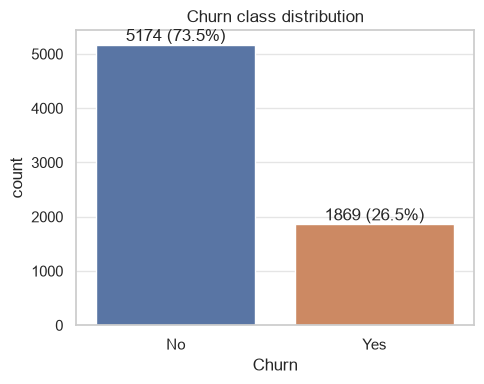

In [10]:
counts = df["Churn"].value_counts()
print(counts)
print((counts / len(df) * 100).round(1))

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x="Churn", hue="Churn",
              palette={"No": "#4C72B0", "Yes": "#DD8452"}, legend=False, ax=ax)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())} ({p.get_height()/len(df):.1%})",
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
ax.set_title("Churn class distribution")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_churn_distribution.png", dpi=150)
plt.show()

# How numeric variables affect the churning

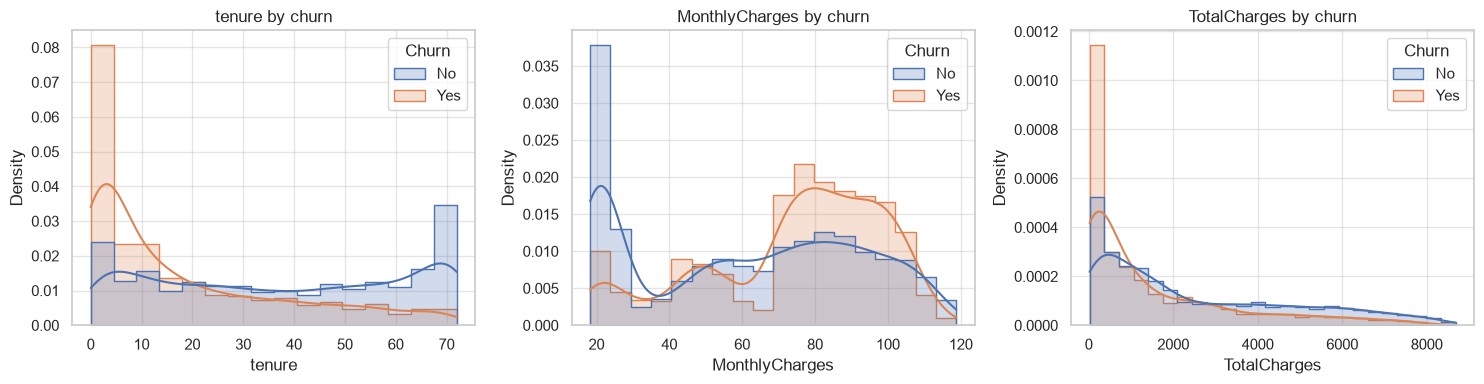

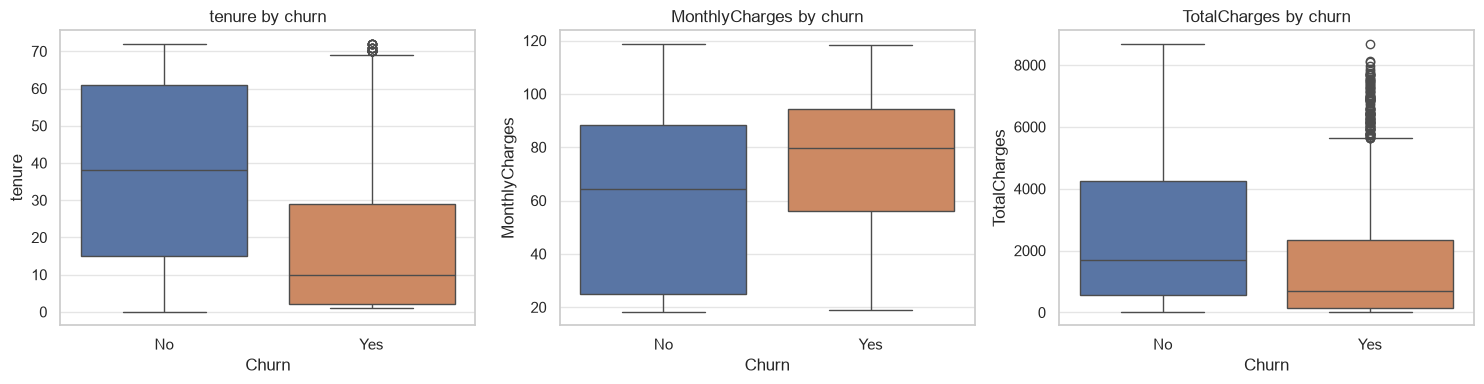

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.425,1683.60
Yes,10.0,79.650,703.55


In [11]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(data=df, x=col, hue="Churn", kde=True, element="step",
                 stat="density", common_norm=False, ax=ax)
    ax.set_title(f"{col} by churn")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_numeric_distributions.png", dpi=150)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x="Churn", y=col, hue="Churn", legend=False, ax=ax)
    ax.set_title(f"{col} by churn")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_numeric_boxplots.png", dpi=150)
plt.show()

df.groupby("Churn")[num_cols].median()

# How categorical variables affect the Churning

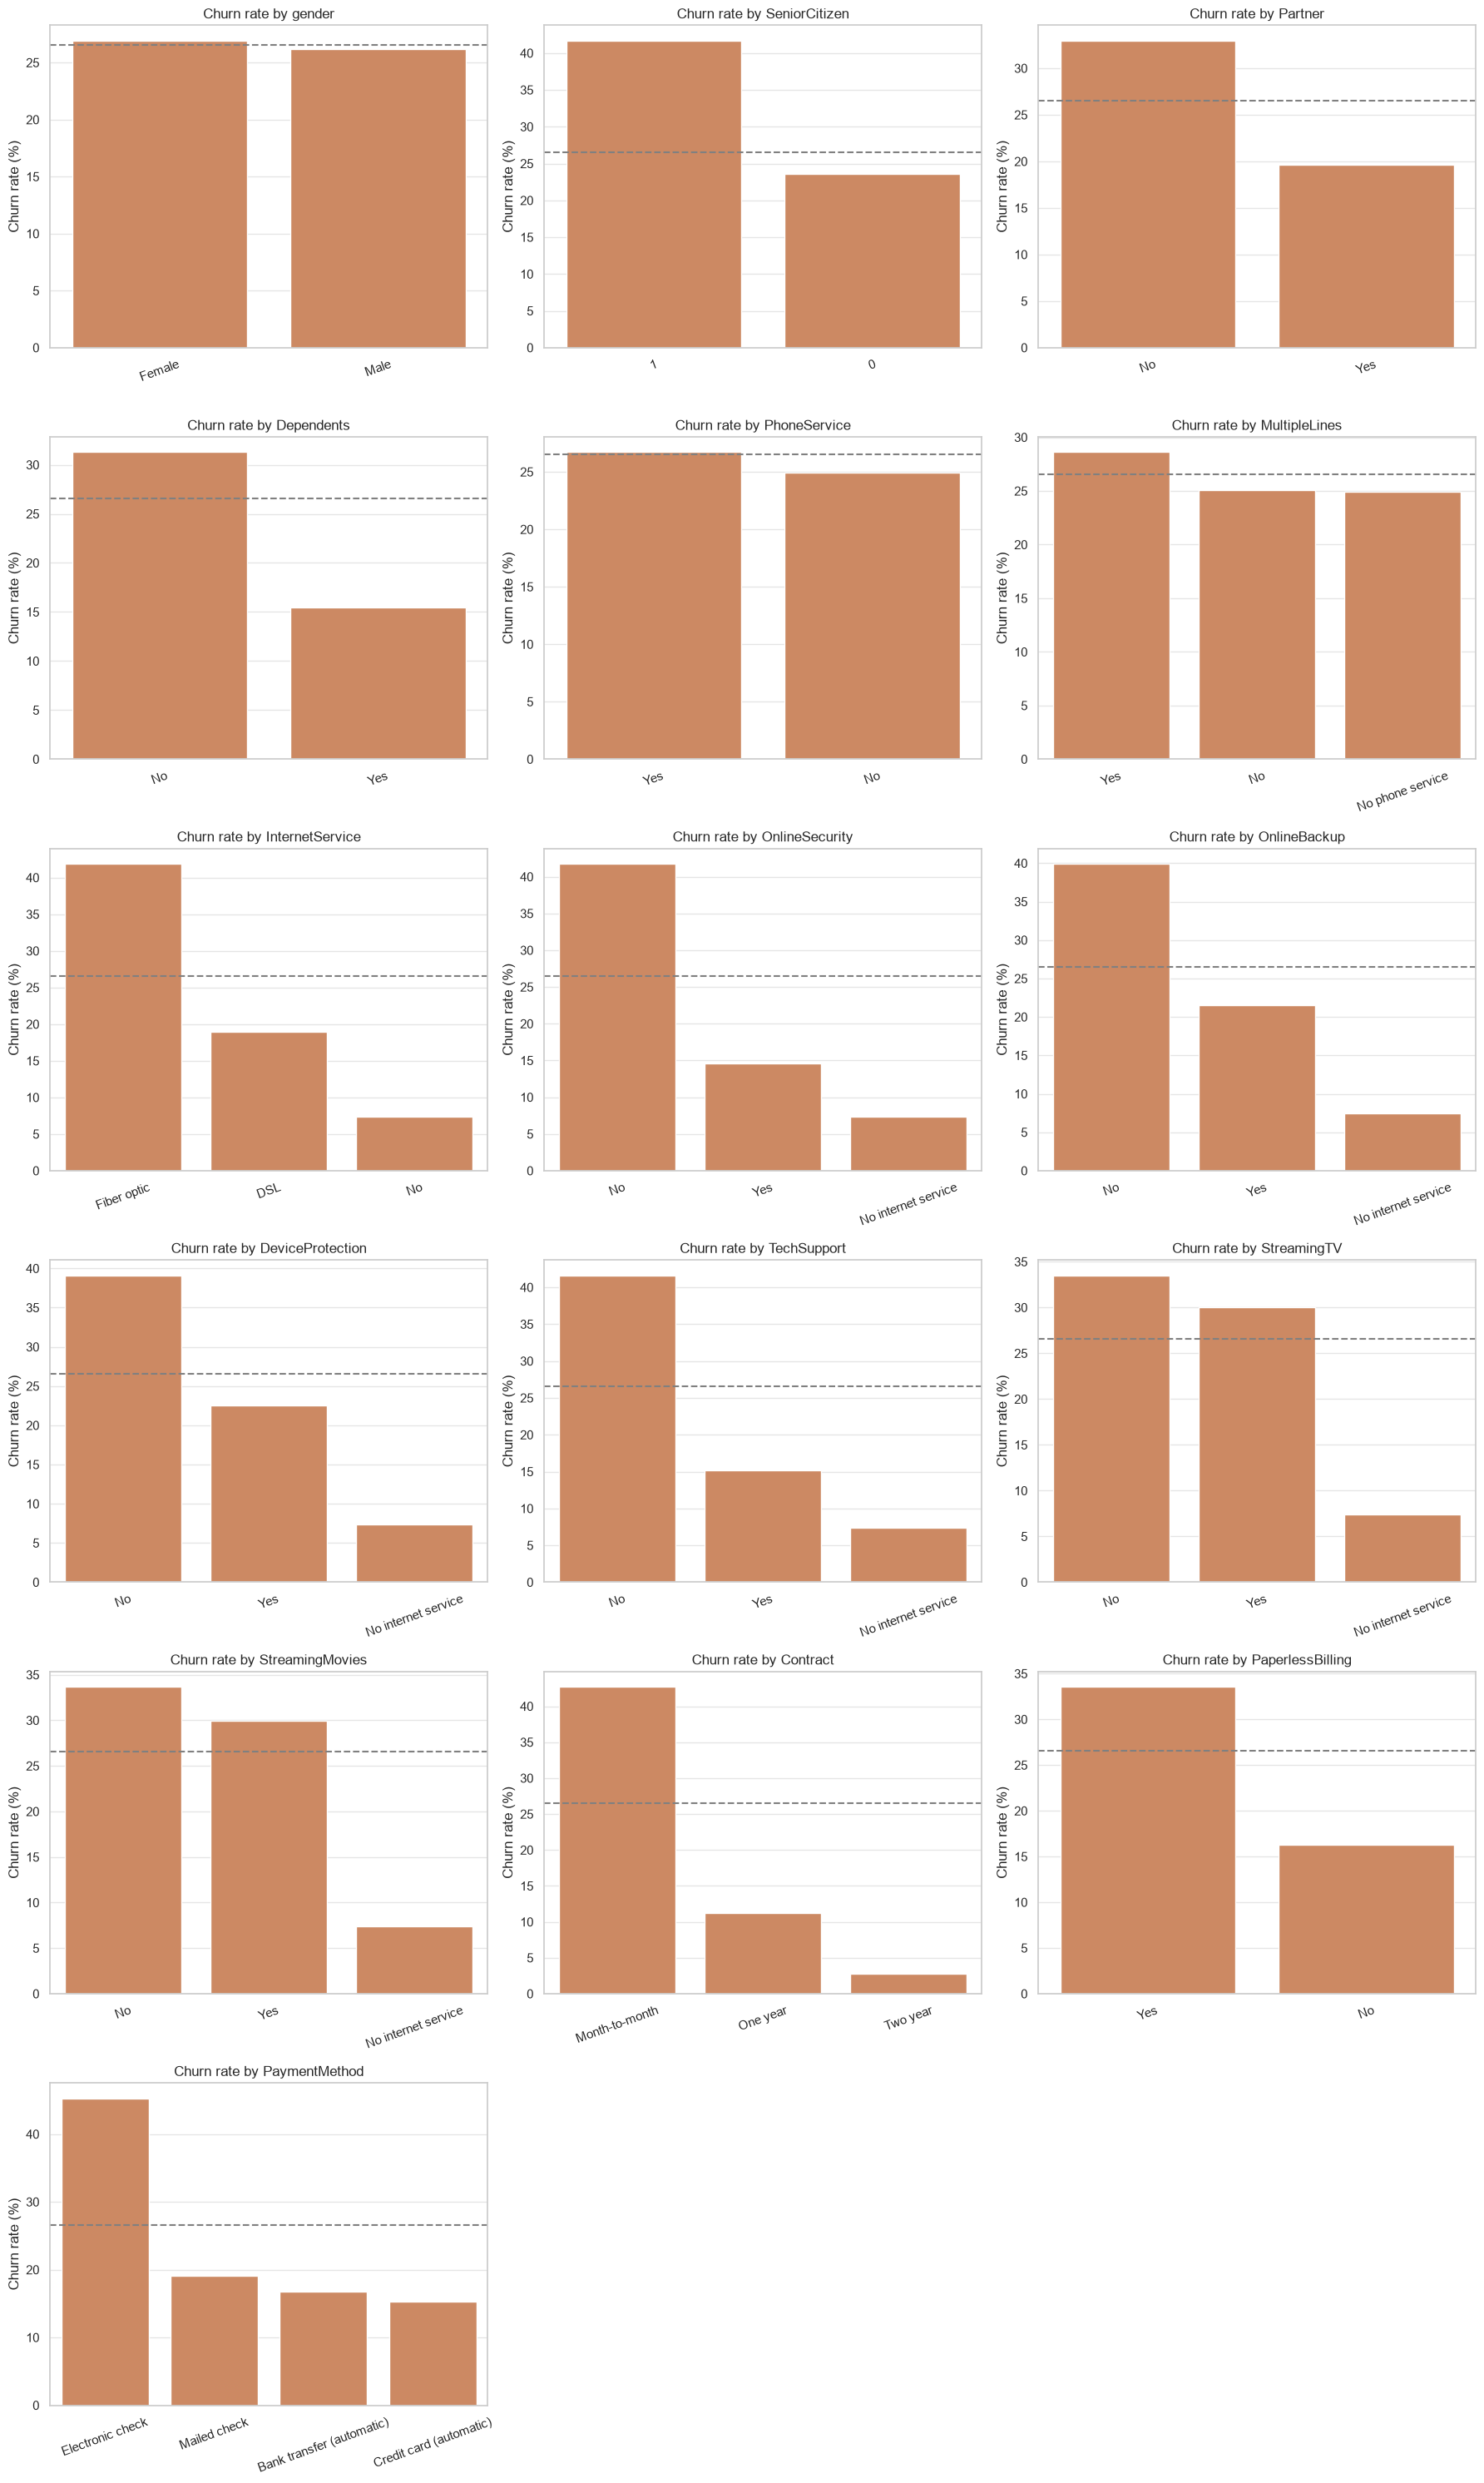

In [12]:
cat_cols = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService",
            "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
            "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
            "Contract", "PaperlessBilling", "PaymentMethod"]
overall_rate = (df["Churn"] == "Yes").mean() * 100

fig, axes = plt.subplots(6, 3, figsize=(18, 30))
axes = axes.flatten()
for ax, col in zip(axes, cat_cols):
    rate = (df.groupby(col)["Churn"]
            .apply(lambda s: (s == "Yes").mean() * 100)
            .sort_values(ascending=False))
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax, color="#DD8452")
    ax.axhline(overall_rate, ls="--", c="grey")   # dashed line = overall churn rate
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("Churn rate (%)")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
for ax in axes[len(cat_cols):]:
    ax.set_visible(False)
plt.tight_layout()
plt.savefig(FIG_DIR / "04_categorical_churn_rates.png", dpi=150)
plt.show()

# Churn by the tenure group

In [13]:
tenure_group = pd.cut(df["tenure"], bins=[0, 12, 24, 48, 72],
                      labels=["0-12", "13-24", "25-48", "49-72"], include_lowest=True)
df.groupby(tenure_group, observed=True)["Churn"].apply(lambda s: (s == "Yes").mean() * 100).round(1)

tenure
0-12     47.4
13-24    28.7
25-48    20.4
49-72     9.5
Name: Churn, dtype: float64

# Correlation Heat Map

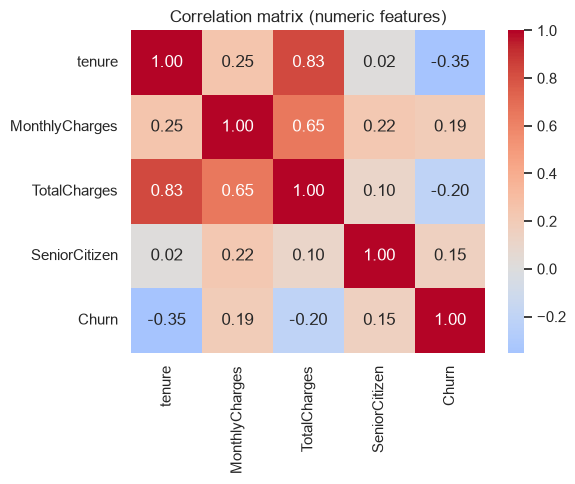

In [14]:
corr_df = df[num_cols + ["SeniorCitizen"]].copy()
corr_df["Churn"] = (df["Churn"] == "Yes").astype(int)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation matrix (numeric features)")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_correlation_heatmap.png", dpi=150)
plt.show()

# KEY INSIGHTS

1) Data quality: There are no duplicates and no nulls. TotalCharges is stored as text, and its 11 blank values all belong to customers with tenure 0 (Haven't done a full month to pay for service). These are new customers who haven’t been billed yet, so the blanks aren’t random errors.
2) Imbalance: 5,174 customers stayed and 1,869 churned, so 26.5% churn. A model that always predicts “No” would score 73.5% accuracy, which is why accuracy alone is misleading here.
3) Tenure is the strongest signal. The median tenure is 10 months for churners and 38 for those who stayed. Churn is 47.4% in the first year and 9.5% after 4 years. The correlation with churn is −0.35.
4) Contract type: Churn is 42.7% on month-to-month contracts, 11.3% on one-year contracts and 2.8% on two-year contracts.
5) Pricing: Churners pay more per month (median $79.65 vs $64.43). Fiber optic customers churn at 41.9%, compared with 19.0% on DSL.
6) Support services: Customers without OnlineSecurity or TechSupport churn at about 42%, compared with about 15% for those who have them.
7) Payment: Electronic check users churn at 45.3%, compared with 15–19% for every other method. Paperless billing customers also churn at 33.6%, compared with 16.3%.
8) Demographics: Gender makes no difference (26.9% vs 26.2%). Senior citizens churn at 41.7% compared with 23.6% for others, and customers with no partner or dependents churn more.
9) PhoneService and MultipleLines barely change the churn rate.